<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS04/datasetPBL/Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Persiapan data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Load 2 dataset
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Gabungkan kedua dataset melalui 'cafe_id'
df = pd.merge(
    df_reviews,
    df_cafes,
    on='cafe_id',
    how='left',
    suffixes=('_review', '_cafe')
)

df.head()

,review_id,cafe_id,author_name,rating_review,text,published_at,likes,scraped_at_review,name,address,latitude,longitude,rating_cafe,review_count,categories,phone,website,scraped_at_cafe,source_query
0,21314615-664d-438a-9f68-142f5b13f4c9,ba4b512c-fa2d-4959-8384-8570c81121ec,Alicia K. Taruli Manurung,5.0,Hore!,11 menit lalu,0,2026-10-11T13:54:49.423310,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
1,ec085c18-dced-4c23-8a65-4f71f93ed181,ba4b512c-fa2d-4959-8384-8570c81121ec,seobchwi fb,5.0,Pelayanan bagus dan ramah apalagi barista yg p...,14 menit lalu,0,2026-10-11T13:54:49.622536,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
2,6f1a2d5a-01c1-4fc9-8cfb-c4f5c8f58ec1,ba4b512c-fa2d-4959-8384-8570c81121ec,Nico Julianda,5.0,"comfort places for everything i did, mulai dar...",22 menit lalu,0,2026-10-11T13:54:49.854029,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
3,fd86734a-dcef-4f6d-8251-e47b203c0199,ba4b512c-fa2d-4959-8384-8570c81121ec,nazira parsa_04,5.0,"minumannya enak"", tempatnya comfy. worth to try",23 menit lalu,0,2026-10-11T13:54:49.967848,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
4,cdeda318-e583-4473-9fd0-4e4b48b56e16,ba4b512c-fa2d-4959-8384-8570c81121ec,dulkamdi dul,5.0,"kopian 24jam enak banget kalau dibuat wfc, tem...",28 menit lalu,0,2026-10-11T13:54:50.058719,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang


In [4]:
# Seleksi Fitur
X = df[['rating_review', 'likes', 'rating_cafe', 'review_count']]
y = df['categories']

X.head()

,rating_review,likes,rating_cafe,review_count
0,5.0,0,4.7,528
1,5.0,0,4.7,528
2,5.0,0,4.7,528
3,5.0,0,4.7,528
4,5.0,0,4.7,528


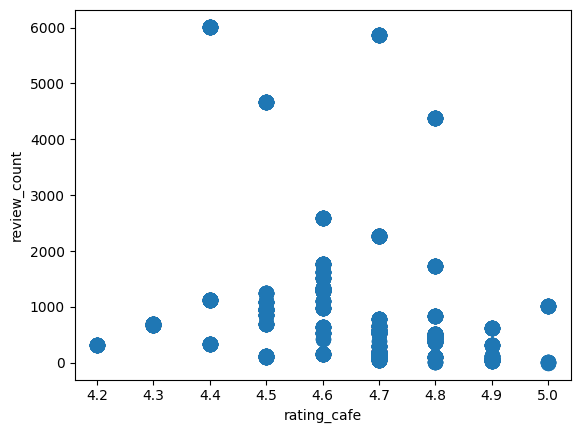

In [5]:
# Plot Data
# Karena data 4 dimensi, kita plot berdasarkan rating_cafe dan review_count saja
plt.scatter(X.iloc[:, 2], X.iloc[:, 3], s=100)
plt.xlabel("rating_cafe")
plt.ylabel("review_count")
plt.show()

In [6]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2
from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2, random_state=42)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

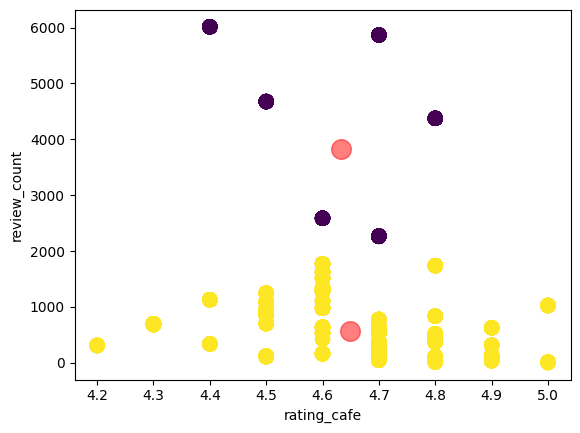

In [7]:
# Plot hasil cluster berdasarkan rating_cafe dan review_count
plt.scatter(X.iloc[:, 2], X.iloc[:, 3], s=100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 2], centers[:, 3], c='red', s=200, alpha=0.5)
plt.xlabel("rating_cafe")
plt.ylabel("review_count")
plt.show()

In [8]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 1025650678.2956342


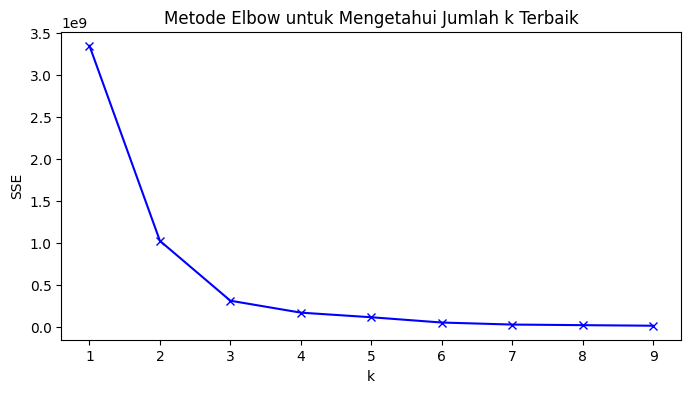

In [9]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-9
K = range(1, 10)

# Cek nilai SSE setiap k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [10]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=3349456237.8207765
k=2; SSE=1025650678.2956342
k=3; SSE=312725849.33784205
k=4; SSE=170631674.04934114
k=5; SSE=115763142.60422665
k=6; SSE=52834418.96104737
k=7; SSE=28748276.01461095
k=8; SSE=21588892.134579472
k=9; SSE=14860765.842993366
